# 🎬 Movie Market Analysis

**Company:** CineData Studios
**Role:** Media Strategy Analyst

## 🎥 Scenario

CineData Studios is planning their next big production. The executive team wants to analyze historical movie data to determine which genres are currently **most profitable** and **highly rated**, helping guide strategic investment decisions.

---

## 🎯 Your Tasks

### 1️⃣ Rating Score Analysis

* Calculate the **average IMDB rating** across all movies in the dataset.
* This represents the overall quality benchmark.

---

### 2️⃣ Genre King 👑

* Group movies by **Genre**.
* Compute the **average rating per genre**.
* Identify which genre has the **highest average rating**.

---

### 3️⃣ Financial Impact Analysis

* Create a **Bar Chart** showing:

```
Genre vs. Box Office Revenue
```

* This will help identify the most financially successful genres.
* Include:

  * Chart title
  * Axis labels
  * Clear formatting

---

### 4️⃣ Rating Distribution

* Create a **Histogram** of movie ratings.

* Include:

  * Title
  * Axis labels
  * Grid (optional)

* Analyze how ratings are distributed across films.

---

### 5️⃣ Success Metric – Hit Identification

* Create a new column called **`Hit`** where:

```
Hit = True  if Rating ≥ 8  
Hit = False if Rating < 8
```

* This helps classify critically successful movies.

---

### 6️⃣ Hit Movie Tally

* Count the total number of **“Hit”** movies in the dataset.
* Optionally calculate the percentage of hits.

---

## 📌 Expected Outcome

By completing this analysis, you should be able to:

* Understand overall movie rating trends
* Identify the highest-rated genres
* Analyze revenue performance by genre
* Recognize critically successful films
* Provide data-driven recommendations for future productions

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv("/content/movie_ratings_dataset.csv")


In [ ]:
df

,Movie_ID,Genre,Duration_Minutes,IMDB_Rating,Box_Office_Millions
0,4001,Thriller,168,6.8,77.3
1,4002,Thriller,155,6.1,132.1
2,4003,Action,125,NaN,276.1
3,4004,Comedy,177,9.5,437.8
4,4005,Action,98,6.2,222.4
5,4006,NaN,109,9.1,289.3
6,4007,Drama,154,6.6,440.9
7,4008,Action,-120,7.3,136.5
8,4009,Thriller,150,7.6,397.3
9,4010,Thriller,104,6.6,486.9


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Movie_ID             22 non-null     int64  
 1   Genre                21 non-null     object 
 2   Duration_Minutes     22 non-null     int64  
 3   IMDB_Rating          21 non-null     float64
 4   Box_Office_Millions  22 non-null     float64
dtypes: float64(2), int64(2), object(1)
memory usage: 1012.0+ bytes


In [ ]:
df = df.drop_duplicates()

In [ ]:
# removing invalid IMDB_rating
df.loc[df["IMDB_Rating"] < 0, "IMDB_Rating"] = None
df.loc[df["IMDB_Rating"] > 10, "IMDB_Rating"] = None


In [ ]:
df.loc[df["Duration_Minutes"] < 0, "Duration_Minutes"] = None     #removing invalid duration
df.loc[df["Box_Office_Millions"] < 0, "Box_Office_Millions"] = None   #removing invalid revenue

In [ ]:
df

,Movie_ID,Genre,Duration_Minutes,IMDB_Rating,Box_Office_Millions
0,4001,Thriller,168.0,6.8,77.3
1,4002,Thriller,155.0,6.1,132.1
2,4003,Action,125.0,NaN,276.1
3,4004,Comedy,177.0,9.5,437.8
4,4005,Action,98.0,6.2,222.4
5,4006,NaN,109.0,9.1,289.3
6,4007,Drama,154.0,6.6,440.9
7,4008,Action,NaN,7.3,136.5
8,4009,Thriller,150.0,7.6,397.3
9,4010,Thriller,104.0,6.6,486.9


In [ ]:
#average IMDB rating
df["IMDB_Rating"].mean().round(2)

np.float64(7.13)

In [ ]:
#Group movies by Genre.
#average rating per genre.

genre_rating = df[df["Genre"] != "Unknown"].groupby("Genre")["IMDB_Rating"].mean()
df

,Movie_ID,Genre,Duration_Minutes,IMDB_Rating,Box_Office_Millions
0,4001,Thriller,168.0,6.8,77.3
1,4002,Thriller,155.0,6.1,132.1
2,4003,Action,125.0,NaN,276.1
3,4004,Comedy,177.0,9.5,437.8
4,4005,Action,98.0,6.2,222.4
5,4006,NaN,109.0,9.1,289.3
6,4007,Drama,154.0,6.6,440.9
7,4008,Action,NaN,7.3,136.5
8,4009,Thriller,150.0,7.6,397.3
9,4010,Thriller,104.0,6.6,486.9


In [ ]:
#highest average rating.
highest_genre = genre_rating.idxmax()

In [ ]:
df

,Movie_ID,Genre,Duration_Minutes,IMDB_Rating,Box_Office_Millions
0,4001,Thriller,168.0,6.8,77.3
1,4002,Thriller,155.0,6.1,132.1
2,4003,Action,125.0,NaN,276.1
3,4004,Comedy,177.0,9.5,437.8
4,4005,Action,98.0,6.2,222.4
5,4006,NaN,109.0,9.1,289.3
6,4007,Drama,154.0,6.6,440.9
7,4008,Action,NaN,7.3,136.5
8,4009,Thriller,150.0,7.6,397.3
9,4010,Thriller,104.0,6.6,486.9


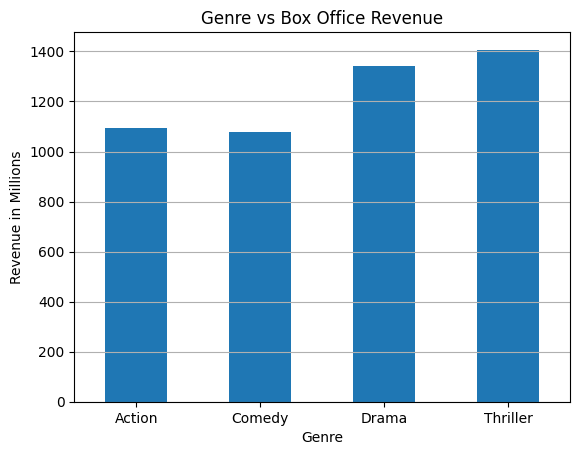

In [ ]:
#GENRE VS BOX OFFICE REVENU

df[df["Genre"] != "Unknown"].groupby("Genre")["Box_Office_Millions"].sum().plot(kind="bar")

plt.title("Genre vs Box Office Revenue")
plt.xlabel("Genre")
plt.ylabel("Revenue in Millions")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

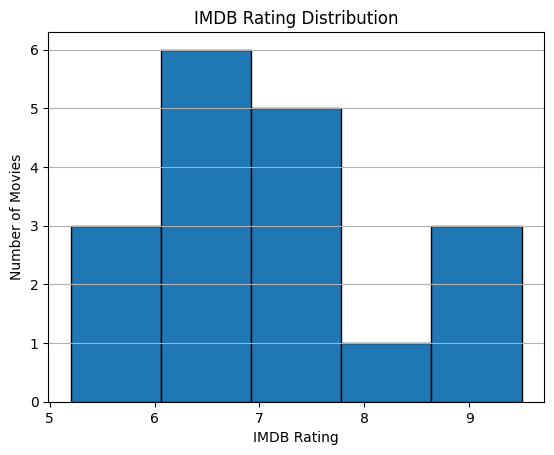

In [ ]:
#IMDB RATING DISTRIBUTION

df["IMDB_Rating"].dropna().plot(kind="hist", bins=5, edgecolor="black")

plt.title("IMDB Rating Distribution")
plt.xlabel("IMDB Rating")
plt.ylabel("Number of Movies")
plt.grid(axis="y")
plt.show()

In [ ]:
#HIT MOVIE IDENTIFICATION

df["Hit"] = df["IMDB_Rating"] >= 8
df[["Movie_ID", "Genre", "IMDB_Rating", "Hit"]]

,Movie_ID,Genre,IMDB_Rating,Hit
0,4001,Thriller,6.8,False
1,4002,Thriller,6.1,False
2,4003,Action,NaN,False
3,4004,Comedy,9.5,True
4,4005,Action,6.2,False
5,4006,NaN,9.1,True
6,4007,Drama,6.6,False
7,4008,Action,7.3,False
8,4009,Thriller,7.6,False
9,4010,Thriller,6.6,False


In [ ]:
#TOTAL HIT MOVIES
df["Hit"].sum()

np.int64(4)

In [ ]:
#HIT MOVIE PERCENTAGE
round((df["Hit"].sum() / df["IMDB_Rating"].count()) * 100, 2)

np.float64(22.22)

In [ ]:
print("\nMOVIE MARKET ANALYSIS COMPLETED")


MOVIE MARKET ANALYSIS COMPLETED
